# Tijdreeks met seizoensinvloeden
Eerst weer data inlezen bij Yahoo Finance en bij de FED in St. Louis:<br>
https://finance.yahoo.com/<br>
https://fred.stlouisfed.org/categories

In [ ]:
! pip install pandas-datareader==0.10.0
! pip install yfinance
! pip install --upgrade yfinance

import yfinance as yf
import pandas as pd
import pandas_datareader.data as web
import datetime as dt
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

from scipy import stats
from sklearn.linear_model import LinearRegression
from datetime import date

#Clear output
from google.colab import output
output.clear()

Alle libraries geinstalleerd, nu de data:

In [ ]:
#yf.pdr_override()

start = dt.datetime(2018,5,1)
end = dt.datetime(2023,5,1)

De grondstoffen en indicatoren:

In [ ]:
inflatie = web.get_data_fred('T10YIE', start, end) #inflatie
rente = web.get_data_fred('FEDFUNDS', start, end) #rente

graan = web.get_data_fred('PWHEAMTUSDM', start, end) #graan
hout = web.get_data_fred('WPU08', start, end) #hout
katoen = web.get_data_fred('PCOTTINDUSDM', start, end) #katoen
koffie = web.get_data_fred('WPU026301', start, end) #koffiebonen
rubber = web.get_data_fred('PRUBBUSDM', start, end) #rubber
vlees = web.get_data_fred('PBEEFUSDM', start, end) #vleesprijs
wol = web.get_data_fred('PWOOLFUSDM', start, end) #wol
zonnebloem = web.get_data_fred('PSUNOUSDM', start, end) #zonnebloemolie

gas = web.get_data_fred('GASREGW', start, end) #gas (US Regular All Formulations Gas Price)
kolen = web.get_data_fred('WPU058103', start, end) #kolen (Producer Price Index by Commodity: Fuels and Related Products and Power: Other Petroleum and Coal Products, Including Coke Oven Products, Not Elsewhere Classified)
oil = yf.download('CL=F', start, end).tz_localize(None) #olie
uranium = web.get_data_fred('PURANUSDM', start, end) #uranium

goud = yf.download('GC=F', start, end).tz_localize(None) #goud future
koper = web.get_data_fred('PCOPPUSDM', start, end) #koperprijs
palladium = yf.download('PA=F', start, end).tz_localize(None) #palladium
staal = web.get_data_fred('WPU101707', start, end) #staal (Producer Price Index by Commodity: Metals and Metal Products: Cold Rolled Steel Sheet and Strip )
zilver = yf.download('SI=F', start, end).tz_localize(None) #zilver future

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


Porfolio's maken van de indicatoren en de grondstoffen:

In [ ]:
indicatoren = pd.concat([rente, inflatie], axis=1)
indicatoren.columns = ["Rente", "Inflatie"]

grondstoffen_1 = pd.concat([graan, koffie, vlees, gas, kolen, hout, katoen, rubber, wol, zonnebloem, uranium], axis=1)
grondstoffen_1.columns = ["Close_Graan", "Close_Koffie", "Close_Vlees", "Close_Gas", "Close_Kolen", "Close_Hout", "Close_Katoen", "Close_Rubber", "Close_Wol", "Close_Zonnebloem", "Close_Uranium"]

grondstoffen_2 = pd.concat([oil.add_suffix("_Olie"), goud.add_suffix("_Goud"), palladium.add_suffix("_Palladium")], axis = 1)
grondstoffen_2 = grondstoffen_2.loc[:, ["Close_Olie", "Close_Goud", "Close_Palladium"]]
grondstoffen_2.columns = ["Close_Olie", "Close_Goud", "Close_Palladium"]

Portfolio-data inlezen:

In [ ]:
apple = yf.download('AAPL', start, end).tz_localize(None) # Apple
shell = yf.download('SHEL', start, end).tz_localize(None) # Shell
ng = yf.download('NOC', start, end).tz_localize(None) # Northrop Grumman
tsm = yf.download('TSM', start, end).tz_localize(None) # Taiwan Semiconductor Manufacturing Company (TSMC)
rio = yf.download('RIO', start, end).tz_localize(None) # Rio Tinto Group
ge = yf.download('GE', start, end).tz_localize(None) # General Electric Company
gs = yf.download('GS', start, end).tz_localize(None) # The Goldman Sachs Group
bond = yf.download('BOND', start, end).tz_localize(None) # PIMCO Active Bond Exchange-Traded Fund
btc = yf.download('BTC-USD', start, end).tz_localize(None) # Bitcoin USD
xrp = yf.download('XRP-USD', start, end).tz_localize(None) # XRP USD

[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


Portfolio-tabel van tabelnamen voorzien, alleen de slotkoersen selecteren en schonen:

In [ ]:
portfolio = pd.concat([apple.add_suffix("_Apple"), shell.add_suffix("_Shell"), ng.add_suffix("_Northrop"),tsm.add_suffix("_TSMC"), rio.add_suffix("_RioTinto"), ge.add_suffix("_GE"), gs.add_suffix("_GoldmanSachs"), bond.add_suffix("_Bond"), btc.add_suffix("_Bitcoin"), xrp.add_suffix("_Ripple")], axis=1)
portfolio_gefilterd = portfolio.loc[:, ["Close_Apple", "Close_Shell", "Close_Northrop", "Close_TSMC","Close_RioTinto","Close_GE","Close_GoldmanSachs","Close_Bond","Close_Bitcoin","Close_Ripple"]]
portfolio_gefilterd.columns = ["Close_Apple", "Close_Shell", "Close_Northrop", "Close_TSMC","Close_RioTinto","Close_GE","Close_GoldmanSachs","Close_Bond","Close_Bitcoin","Close_Ripple"]
nans_gevuld = portfolio_gefilterd.ffill()
nans_gevuld

,Close_Apple,Close_Shell,Close_Northrop,Close_TSMC,Close_RioTinto,Close_GE,Close_GoldmanSachs,Close_Bond,Close_Bitcoin,Close_Ripple
Date,,,,,,,,,,
2018-05-01,42.275002,69.050003,307.220001,38.930000,54.560001,67.333748,236.669998,102.639999,9119.009766,0.841407
2018-05-02,44.142502,69.180000,307.160004,37.750000,55.020000,67.956764,234.050003,102.589996,9235.919922,0.859094
2018-05-03,44.222500,69.610001,315.679993,38.099998,55.459999,66.758652,233.410004,102.580002,9743.860352,0.884466
2018-05-04,45.957500,69.839996,313.850006,38.590000,55.619999,67.573364,234.940002,102.709999,9700.759766,0.895442
2018-05-05,45.957500,69.839996,313.850006,38.590000,55.619999,67.573364,234.940002,102.709999,9858.150391,0.905103
...,...,...,...,...,...,...,...,...,...,...
2023-04-26,163.759995,60.490002,449.089996,82.250000,62.939999,76.783722,336.559998,92.889999,28422.701172,0.462037
2023-04-27,168.410004,60.680000,457.679993,83.669998,63.700001,78.260178,341.600006,92.660004,29473.787109,0.466868
2023-04-28,169.679993,61.980000,461.269989,84.300003,63.990002,78.986435,343.440002,93.120003,29340.261719,0.480271


En nu het 'piece-de-resistance': alles samenvoegen:

In [ ]:
apt = pd.concat([nans_gevuld, indicatoren, grondstoffen_1, grondstoffen_2], axis=1)
apt_fill = apt.ffill()
apt_fill

,Close_Apple,Close_Shell,Close_Northrop,Close_TSMC,Close_RioTinto,Close_GE,Close_GoldmanSachs,Close_Bond,Close_Bitcoin,Close_Ripple,...,Close_Kolen,Close_Hout,Close_Katoen,Close_Rubber,Close_Wol,Close_Zonnebloem,Close_Uranium,Close_Olie,Close_Goud,Close_Palladium
2018-05-01,42.275002,69.050003,307.220001,38.930000,54.560001,67.333748,236.669998,102.639999,9119.009766,0.841407,...,595.400,249.700,94.478571,76.123690,1648.876010,938.999457,21.978261,67.250000,1303.800049,938.450012
2018-05-02,44.142502,69.180000,307.160004,37.750000,55.020000,67.956764,234.050003,102.589996,9235.919922,0.859094,...,595.400,249.700,94.478571,76.123690,1648.876010,938.999457,21.978261,67.930000,1302.599976,962.349976
2018-05-03,44.222500,69.610001,315.679993,38.099998,55.459999,66.758652,233.410004,102.580002,9743.860352,0.884466,...,595.400,249.700,94.478571,76.123690,1648.876010,938.999457,21.978261,68.430000,1310.699951,960.900024
2018-05-04,45.957500,69.839996,313.850006,38.590000,55.619999,67.573364,234.940002,102.709999,9700.759766,0.895442,...,595.400,249.700,94.478571,76.123690,1648.876010,938.999457,21.978261,69.720001,1312.699951,959.450012
2018-05-05,45.957500,69.839996,313.850006,38.590000,55.619999,67.573364,234.940002,102.709999,9858.150391,0.905103,...,595.400,249.700,94.478571,76.123690,1648.876010,938.999457,21.978261,69.720001,1312.699951,959.450012
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2023-04-27,168.410004,60.680000,457.679993,83.669998,63.700001,78.260178,341.600006,92.660004,29473.787109,0.466868,...,859.822,303.442,95.132500,69.801145,1086.543200,1267.779792,41.762017,74.760002,1989.900024,1500.400024
2023-04-28,169.679993,61.980000,461.269989,84.300003,63.990002,78.986435,343.440002,93.120003,29340.261719,0.480271,...,859.822,303.442,95.132500,69.801145,1086.543200,1267.779792,41.762017,76.779999,1990.099976,1517.900024
2023-04-29,169.679993,61.980000,461.269989,84.300003,63.990002,78.986435,343.440002,93.120003,29248.488281,0.478409,...,859.822,303.442,95.132500,69.801145,1086.543200,1267.779792,41.762017,76.779999,1990.099976,1517.900024
2023-04-30,169.679993,61.980000,461.269989,84.300003,63.990002,78.986435,343.440002,93.120003,29268.806641,0.472332,...,859.822,303.442,95.132500,69.801145,1086.543200,1267.779792,41.762017,76.779999,1990.099976,1517.900024


# Seasonal decomposing
Kunnen we een plaatje maken met daarin per variabele apart de trend, de seizoensinvloed en een ' rest'-invloed? Ja, dat kan:

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose

decompose_result = seasonal_decompose(apt_fill['Close_Apple'], period=12)

df_trend = decompose_result.trend
df_season = decompose_result.seasonal
df_residual = decompose_result.resid

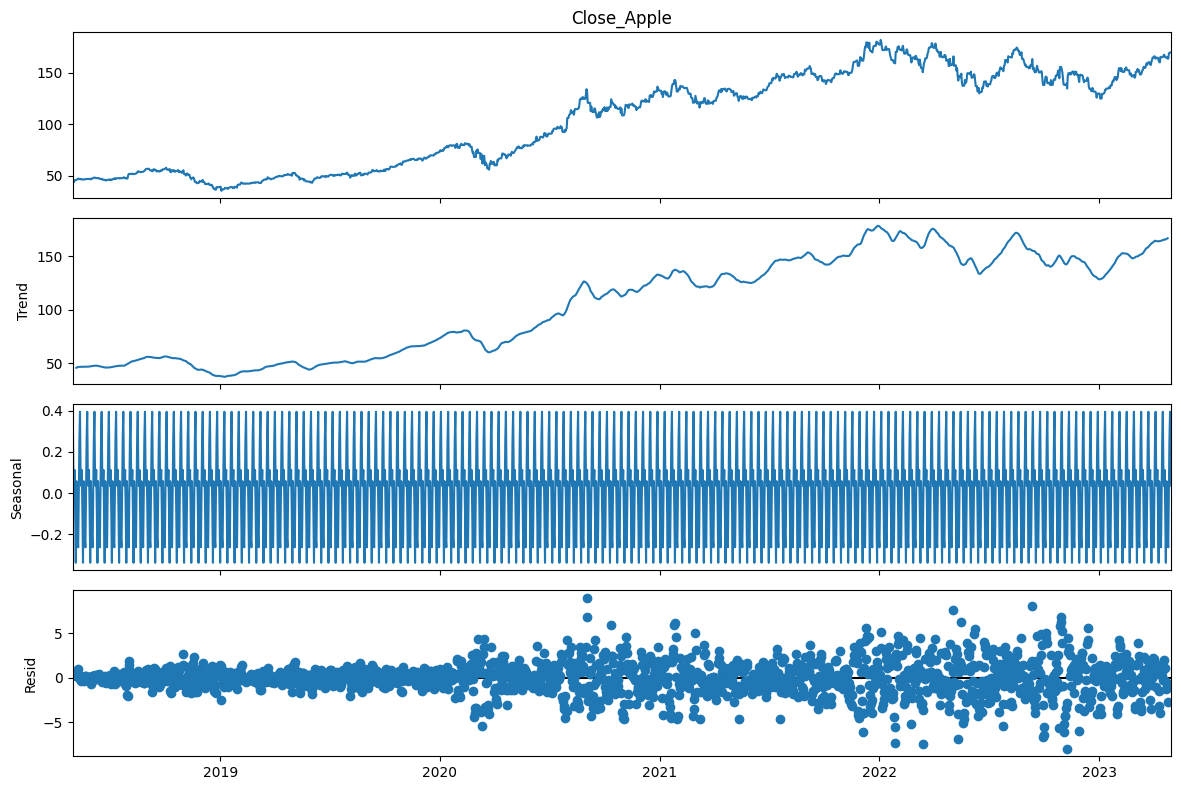

In [ ]:
plt.rcParams['figure.figsize'] = (12, 8)
fig = decompose_result.plot()

De trend in de koers van Apple gedurende de periode mei 2018- mei 2023 is positief.<br>
De seizoensinvloed op de koers is volledig regelmatig afwisselend positief en negatief: dat duidt op een 'random walk'.<br>
In de grafiek van de residuen is te zien dat de afwijkingen ten opzichte van de 'gemiddelde' trend lijken toe te nemen met de tijd: er is meer onzekerheid ten aanzien van de koers in 2022 (en 2023) dan in 2018 en 2019.<br>
https://www.statsmodels.org/dev/generated/statsmodels.tsa.seasonal.seasonal_decompose.html

In [ ]:
# @title tabular presentation year-end close composition

# Close_Apple = Trend + Seasonality + Residual

def print_time_series_table(data_dict):
    """
    Print time series data in a tabular format.

    Parameters:
    data_dict (dict): Dictionary with row labels as keys and series of values as values,
                      including a 'dates' key for the column headers
    """
    # Print each row of data
    for label, values in data_dict.items():
        print(f"{label:20}", end='')
        # Format each value
        for value in values:
            if isinstance(value, dt.datetime):  # Check if value is datetime
                print(f"{value.strftime('%d-%m-%Y'):>20}", end='')
            else:  # Treat as float
                print(f"{value:>20.3f}", end='')
        print()

year_end_dates = [dt.datetime(year, 12, 31) for year in range(start.year, end.year)]

data = {
    'Date': year_end_dates,
    'Close_Apple ($)': apt_fill['Close_Apple'][year_end_dates],
    'Trend ($)': df_trend[year_end_dates],
    'Seasonality ($)': df_season[year_end_dates],
    'Residual ($)': df_residual[year_end_dates]
}

print_time_series_table(data)

Date                          31-12-2018          31-12-2019          31-12-2020          31-12-2021          31-12-2022
Close_Apple ($)                   39.435              73.412             132.690             177.570             129.930
Trend ($)                         38.368              73.392             132.474             178.080             128.704
Seasonality ($)                   -0.092              -0.263               0.112              -0.216               0.093
Residual ($)                       1.159               0.284               0.104              -0.294               1.133


# Is er een seizoensinvloed in de koers van Apple?
We gaan onderzoeken of er een maand-effect te vinden is in de koersdata van Apple (in dit voorbeeld). Eerst maken we een nieuw dataframe waarop we de regressie kunnen draaien. We gaan uit van de tabel hierboven (apt_fill), selecteren alleen de koers van Apple (kolomnummer 0) en voegen een tijd en maand-kolom toe:

In [ ]:
aandeel = 0

seizoen = apt_fill.iloc[:,aandeel].reset_index().reset_index()
seizoen['Month'] = pd.DatetimeIndex(seizoen['index']).month
seizoen = seizoen.rename(columns = {'level_0' : 'Time'})
seizoen

,Time,index,Close_Apple,Month
0,0,2018-05-01,42.275002,5
1,1,2018-05-02,44.142502,5
2,2,2018-05-03,44.222500,5
3,3,2018-05-04,45.957500,5
4,4,2018-05-05,45.957500,5
...,...,...,...,...
1822,1822,2023-04-27,168.410004,4
1823,1823,2023-04-28,169.679993,4
1824,1824,2023-04-29,169.679993,4
1825,1825,2023-04-30,169.679993,4


Vervolgens vullen we dit dataframe aan met de verschillende maanden tot en met november (M1 t/m M11):

In [ ]:
for i in range(1,12):
  seizoen["M" + str(i)] = np.where(seizoen["Month"] == i, 1,0)
seizoen

,Time,index,Close_Apple,Month,M1,M2,M3,M4,M5,M6,M7,M8,M9,M10,M11
0,0,2018-05-01,42.275002,5,0,0,0,0,1,0,0,0,0,0,0
1,1,2018-05-02,44.142502,5,0,0,0,0,1,0,0,0,0,0,0
2,2,2018-05-03,44.222500,5,0,0,0,0,1,0,0,0,0,0,0
3,3,2018-05-04,45.957500,5,0,0,0,0,1,0,0,0,0,0,0
4,4,2018-05-05,45.957500,5,0,0,0,0,1,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1822,1822,2023-04-27,168.410004,4,0,0,0,1,0,0,0,0,0,0,0
1823,1823,2023-04-28,169.679993,4,0,0,0,1,0,0,0,0,0,0,0
1824,1824,2023-04-29,169.679993,4,0,0,0,1,0,0,0,0,0,0,0
1825,1825,2023-04-30,169.679993,4,0,0,0,1,0,0,0,0,0,0,0


Als X = onafhankelijke variabelen selecteren we alleen de Tijd en de Maanden, de rest verwijderen we:

In [ ]:
X = seizoen.copy()
X.drop(seizoen.columns[[1, 2, 3]], axis = 1, inplace= True)
X

,Time,M1,M2,M3,M4,M5,M6,M7,M8,M9,M10,M11
0,0,0,0,0,0,1,0,0,0,0,0,0
1,1,0,0,0,0,1,0,0,0,0,0,0
2,2,0,0,0,0,1,0,0,0,0,0,0
3,3,0,0,0,0,1,0,0,0,0,0,0
4,4,0,0,0,0,1,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
1822,1822,0,0,0,1,0,0,0,0,0,0,0
1823,1823,0,0,0,1,0,0,0,0,0,0,0
1824,1824,0,0,0,1,0,0,0,0,0,0,0
1825,1825,0,0,0,1,0,0,0,0,0,0,0


Als te verklaren = afhankelijke variabele selecteren we de koers van Apple:

In [ ]:
y = seizoen[seizoen.columns[2]]
y

,Close_Apple
0,42.275002
1,44.142502
2,44.222500
3,45.957500
4,45.957500
...,...
1822,168.410004
1823,169.679993
1824,169.679993
1825,169.679993


Nu kunnen we de regressie uitvoeren:

In [ ]:
X = sm.add_constant(X)
reg = sm.OLS(y, X).fit()
print(reg.summary())

                            OLS Regression Results                            
Dep. Variable:            Close_Apple   R-squared:                       0.871
Model:                            OLS   Adj. R-squared:                  0.870
Method:                 Least Squares   F-statistic:                     1021.
Date:                Mon, 02 Dec 2024   Prob (F-statistic):               0.00
Time:                        14:48:06   Log-Likelihood:                -7705.4
No. Observations:                1827   AIC:                         1.544e+04
Df Residuals:                    1814   BIC:                         1.551e+04
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         31.9456      1.505     21.231      0.0

We zien dat het model niet geldig is: de p-waarden van M1, M2, M4, M5, M7, M9, M10 en M11 zijn groter dan 0,05. <br>
Verder zijn van alle maanden behalve juli, augustus en september de coefficienten negatief:<br>kennelijk ligt de koers in al die maanden lager (dan in december).<br>
De coefficient van de Tijd is klein maar positief: er is een lichte opwaartse trend in de koersdata van Apple.

# Is er een seizoensinvloed in de prijs van kolen?
We voeren dezelfde stappen uit, maar nu voor de (maand)prijs van kolen (kolomnummer 16):

In [ ]:
aandeel = 16

seizoen = apt_fill.iloc[:,aandeel].reset_index().reset_index()
seizoen['Month'] = pd.DatetimeIndex(seizoen['index']).month
seizoen = seizoen.rename(columns = {'level_0' : 'Time'})
seizoen

,Time,index,Close_Kolen,Month
0,0,2018-05-01,595.400,5
1,1,2018-05-02,595.400,5
2,2,2018-05-03,595.400,5
3,3,2018-05-04,595.400,5
4,4,2018-05-05,595.400,5
...,...,...,...,...
1822,1822,2023-04-27,859.822,4
1823,1823,2023-04-28,859.822,4
1824,1824,2023-04-29,859.822,4
1825,1825,2023-04-30,859.822,4


In [ ]:
for i in range(1,12):
  seizoen["M" + str(i)] = np.where(seizoen["Month"] == i, 1,0)
seizoen

,Time,index,Close_Kolen,Month,M1,M2,M3,M4,M5,M6,M7,M8,M9,M10,M11
0,0,2018-05-01,595.400,5,0,0,0,0,1,0,0,0,0,0,0
1,1,2018-05-02,595.400,5,0,0,0,0,1,0,0,0,0,0,0
2,2,2018-05-03,595.400,5,0,0,0,0,1,0,0,0,0,0,0
3,3,2018-05-04,595.400,5,0,0,0,0,1,0,0,0,0,0,0
4,4,2018-05-05,595.400,5,0,0,0,0,1,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1822,1822,2023-04-27,859.822,4,0,0,0,1,0,0,0,0,0,0,0
1823,1823,2023-04-28,859.822,4,0,0,0,1,0,0,0,0,0,0,0
1824,1824,2023-04-29,859.822,4,0,0,0,1,0,0,0,0,0,0,0
1825,1825,2023-04-30,859.822,4,0,0,0,1,0,0,0,0,0,0,0


In [ ]:
X = seizoen.copy()
X.drop(seizoen.columns[[1, 2, 3]], axis = 1, inplace= True)
X

,Time,M1,M2,M3,M4,M5,M6,M7,M8,M9,M10,M11
0,0,0,0,0,0,1,0,0,0,0,0,0
1,1,0,0,0,0,1,0,0,0,0,0,0
2,2,0,0,0,0,1,0,0,0,0,0,0
3,3,0,0,0,0,1,0,0,0,0,0,0
4,4,0,0,0,0,1,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
1822,1822,0,0,0,1,0,0,0,0,0,0,0
1823,1823,0,0,0,1,0,0,0,0,0,0,0
1824,1824,0,0,0,1,0,0,0,0,0,0,0
1825,1825,0,0,0,1,0,0,0,0,0,0,0


In [ ]:
y = seizoen[seizoen.columns[2]]
y

,Close_Kolen
0,595.400
1,595.400
2,595.400
3,595.400
4,595.400
...,...
1822,859.822
1823,859.822
1824,859.822
1825,859.822


In [ ]:
X = sm.add_constant(X)
reg = sm.OLS(y, X).fit()
print(reg.summary())

                            OLS Regression Results                            
Dep. Variable:            Close_Kolen   R-squared:                       0.592
Model:                            OLS   Adj. R-squared:                  0.589
Method:                 Least Squares   F-statistic:                     219.5
Date:                Mon, 02 Dec 2024   Prob (F-statistic):               0.00
Time:                        14:52:26   Log-Likelihood:                -11558.
No. Observations:                1827   AIC:                         2.314e+04
Df Residuals:                    1814   BIC:                         2.321e+04
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        452.1531     12.396     36.474      0.0

Conclusie?